# 03MIAR - Algoritmos de optimización
## Actividad guiada 2

*Lucas Tamara Trejo*

Repositorio con el notebook y el PDF: https://github.com/lucastamaraucv/AG2



## Presentación

Profesor:
- Grupos A2, A3, B1, B2: David Álvarez Robles (dalvarezr@professor.universidadviu.com)

## Objetivos
- Comprender la utilidad y aplicar algoritmos dinámicos
- Comprender la utilidad y aplicar algoritmos de ramificación y poda
- Comprender la utilidad y aplicar el algoritmo de optimización por descenso de gradiente

## Programación dinámica - Problema del viaje por el río
- Se divide el problema en subproblemas más pequeños para poder usar las soluciones más adelante
- Si el problema verifica el principio de optimalidad de Bellman "en una secuencia óptima de decisiones, toda sub-secuencia es también óptima" esto funciona bien
- Guardar soluciones parciales + recursividad = complejidad

In [17]:
import math

i = float("inf")

tarifas = [
    [0, 5, 4, 3, i, i, i],
    [i, 0, i, 2, 3, i, 11],
    [i, i, 0, 1, i, 4, 10],
    [i, i, i, 0, 5, 6, 9],
    [i, i, i, i, 0, i ,4],
    [i, i, i, i, i, 0, 3],
    [i, i, i, i, i, i, 0]
]

# Función para obtener precios finales entre dos nodos y qué rutas seguir
def obtener_precios_y_rutas(tarifas):
    # Inicialización de tabla de precios y rutas (precios a infinito como peor caso)
    nodos = len(tarifas[0])
    precios = [[i]*nodos for i in [float("inf")]*nodos]
    ruta = [[i]*nodos for i in [""]*nodos]

    # Recorremos todos los caminos (desde "n" hasta un "n" superior -> Ej: 0 a 1, 0 a 2, 1 a 4... pero nunca de 1 a 0 o de 4 a 2)
    for i in range(nodos-1):
        for j in range(i+1,nodos):

            # Asumimos que el mínimo es la tarifa de un nodo a otro inicialmente
            minimo = tarifas[i][j]
            # Asumimos que la mejor ruta de un nodo a otro comienza en el nodo inicial (ej: 0,1 -> 0, 0,4 -> 0, 2,5 -> 2)
            ruta[i][j] = i

            # Recorremos posibles movimientos intermedios
            for k in range(i,j):
                #print(precios)
                #print(f"i: {i}, j: {j}, k: {k}, precios_ik: {precios[i][k]}, tarifas_kj: {tarifas[k][j]}")
                # Si el precio de ir de i a k más la tarifa de k a j es menor que la tarifa de i a j, nos quedamos con esa ruta
                if (precios[i][k] + tarifas[k][j] < minimo):
                    minimo = precios[i][k] + tarifas[k][j]
                    ruta[i][j] = k
                # Actualizamos precio de i a j como el mínimo (puede ser pasando por k)
                precios[i][j] = minimo

    # Retornamos tabla de precios y de rutas de un nodo a otro
    return precios, ruta

# Función que calcula la ruta óptima a seguir
def calcular_ruta(ruta, inicio, fin, resultado = []):
    # Si el nodo inicial es igual al final, devolvemos el nodo
    if inicio == fin:
        #print(f"{inicio}")
        resultado.append(inicio)
        return resultado
    # Si tengo que desplazarme, calculo recursivamente la ruta de inicio a final siguiendo la tabla de rutas
    else:
        #print(f"{fin}")
        resultado.append(fin)
        return calcular_ruta(ruta, inicio, ruta[inicio][fin])

precios, ruta = obtener_precios_y_rutas(tarifas)

for fila in precios:
  print(fila)
print("---")
for fila in ruta:
  print(fila)

desde=0
hasta=6
resultado = calcular_ruta(ruta, desde, hasta)
print("---")
print(f"Ruta a seguir: {resultado[::-1]}")

[inf, 5, 4, 3, 8, 8, 11]
[inf, inf, inf, 2, 3, 8, 7]
[inf, inf, inf, 1, 6, 4, 7]
[inf, inf, inf, inf, 5, 6, 9]
[inf, inf, inf, inf, inf, inf, 4]
[inf, inf, inf, inf, inf, inf, 3]
[inf, inf, inf, inf, inf, inf, inf]
---
['', 0, 0, 0, 1, 2, 5]
['', '', 1, 1, 1, 3, 4]
['', '', '', 2, 3, 2, 5]
['', '', '', '', 3, 3, 3]
['', '', '', '', '', 4, 4]
['', '', '', '', '', '', 5]
['', '', '', '', '', '', '']
---
Ruta a seguir: [0, 2, 5, 6]


## Ramificación y poda - Problema de las tareas
- Se necesitan funciones auxiliares para calcular todo el grafo (árbol)
- Función para calcular costes de soluciones parciales (no completas)
- Función para calcular cota inferior (muy optimista, repitiendo tareas si es necesario aunque la poda sea peor)
- Función para crear hijos e ir construyendo las soluciones
- Función para ramificar nodos y podar

In [18]:
import itertools
import math

costes = [
    [11,12,18,40],
    [14,15,13,22],
    [11,17,19,23],
    [17,14,20,28]
]

#for s in itertools.permutations(range(len(costes))):
#  print(s)

In [19]:
def fuerza_bruta(costes):

    optimo = float("inf")

    for s in itertools.permutations(range(len(costes))):
        coste = sum(costes[i][s[i]] for i in range(len(costes))) # Acumulo costes de cada agente
        if (coste < optimo):
            tareas, optimo = s, coste

    return tareas, optimo

tareas, optimo = fuerza_bruta(costes)
print(f"Obtenida mejor solución {tareas} con coste {optimo} por fuerza bruta")

Obtenida mejor solución (0, 2, 3, 1) con coste 61 por fuerza bruta


In [20]:
def coste_parcial(solucion, costes):
    coste = 0

    for i in range(len(solucion)):
        coste += costes[i][solucion[i]]

    return coste

#coste = coste_parcial((0,1),costes) # 11 + 15 = 26
#print(coste)

In [21]:
def cota_inferior(solucion, costes):
    # Calculo el coste parcial de la solución dada
    coste = coste_parcial(solucion,costes)

    # Calculo coste mínimo de opciones restantes no usadas permitiendo reutilización por sencillez (relajación = menos poda)
    no_usadas = set(range(len(costes)))-set(solucion)

    for i in range(len(solucion),len(costes)):
        coste += min([costes[i][j] for j in no_usadas])

    return coste

#CI = cota_inferior((0,1),costes)
#print(CI)

In [22]:
# def cota_superior(solucion, costes):
#     # Calculo el coste parcial de la solución dada
#     coste = coste_parcial(solucion,costes)

#     # Calculo coste máximo de opciones restantes no usadas
#     no_usadas = set(range(len(costes)))-set(solucion)

#     for i in range(len(solucion),len(costes)):
#         coste += max([costes[i][j] for j in no_usadas])

#     return coste

# CS = cota_superior((0,1),costes)
# print(CS)

In [23]:
# Función para crear las ramas del árbol
def crear_hijos(solucion, dimension):
  hijos = []
  for i in range(dimension):
    if i not in solucion:
      hijos.append({'s':solucion + (i,)})
  return hijos

#crear_hijos((0,1),4)

In [24]:
def ramificacion_y_poda(costes):

    dimension = len(costes)

    # Inicializo solución a vacío con el peor coste posible
    mejor_solucion = tuple(i for i in range(dimension))
    mejor_coste = coste_parcial(mejor_solucion,costes)

    # Creo un array de nodos y lo inicializo con una solución vacía (para comenzar por algo)
    nodos = []
    nodos.append({'s':(), 'ci':cota_inferior((),costes)})

    # Llevo cuenta de iteraciones por debugging
    iteracion = 0

    # Mientras haya nodos por explorar, aplico ramificación y poda
    while(nodos):
        # Cojo el nodo más prometedor (menor cota inferior, aunque esto luego puede ser "peor" a posteriori)
        nodo = min(nodos, key=lambda x: x['ci'])

        # Ramifico el nodo para obtener sus hijos
        hijos = crear_hijos(nodo['s'],dimension)

        # Para cada hijo, hago el procesamiento adecuado antes de decidir si es solución completa o un nuevo nodo
        for hijo in hijos:

            # Si la dimensión de la solución es igual a la dimensión de costes, es una solución final
            if (len(hijo['s']) == dimension):
                # Calculo el coste de la solución obtenida en el árbol
                coste = coste_parcial(hijo['s'],costes)
                # Si el coste es mejor, me lo quedo como solución
                if (coste < mejor_coste):
                    mejor_solucion = hijo['s']
                    mejor_coste = coste

            # Si la dimensión de la solución no es igual a la dimensión de costes, aplico poda
            else:
                # Calculo cota inferior del hijo
                cota_inferior_hijo = cota_inferior(hijo['s'], costes)
                # Si la cota inferior es menor que el mejor coste, lo añado a la lista de nodos a actualizar
                # Si la cota inferior fuera mayor, no tiene sentido porque no puede mejorar mi solución -> Poda
                if (cota_inferior_hijo <= mejor_coste):
                    nodos.append({'s':hijo['s'], 'ci':cota_inferior_hijo})
                #else:
                    #print(mejor_coste)
                    #print(f"Nodo eliminado: {hijo['s']} con cota inferior {cota_inferior_hijo}")

        # Elimino el nodo ya mirado
        nodos.remove(nodo)

        # Llevo la cuenta de las iteraciones que hago
        iteracion += 1

    return iteracion, mejor_solucion, mejor_coste

iteraciones, mejor_solucion, mejor_coste = ramificacion_y_poda(costes)
print(f"Obtenida mejor solución {mejor_solucion} con coste {mejor_coste} en {iteraciones} iteraciones")

Obtenida mejor solución (0, 2, 3, 1) con coste 61 en 17 iteraciones


## Descenso del gradiente - Optimización de funciones
- Se lleva a cabo una optimización basada en el método del descenso de gradiente
- Se calcula el vector de derivadas parciales y se minimiza la función objetivo actualizando los nuevos puntos (ver figura)

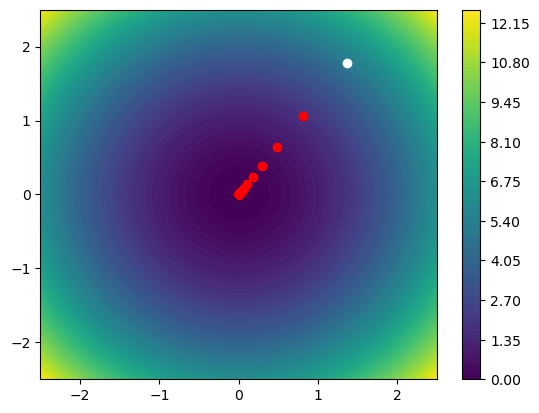

In [25]:
import math
import matplotlib.pyplot as plt
import numpy as np
import random

f = lambda X : X[0]**2 + X[1]**2 # x^2 + y^2
df = lambda X : [2*X[0] , 2*X[1]] # (2x, 2y)

resolucion = 100
rango = 2.5
X = np.linspace(-rango, rango, resolucion)
Y = np.linspace(-rango, rango, resolucion)
Z = np.zeros([resolucion, resolucion])

for ix, x in enumerate(X):
    for iy, y in enumerate(Y):
        Z[ix,iy] = f([x,y])

plt.contourf(X, Y, Z, resolucion)
plt.colorbar()

P = [random.uniform(-2,2), random.uniform(-2,2)]
plt.plot(P[0],P[1],"o",c="white")

tasa_aprendizaje = 0.2
for _ in range(500):
    grad = df(P)
    P[0], P[1] = P[0] - tasa_aprendizaje*grad[0], P[1] - tasa_aprendizaje*grad[1]
    plt.plot(P[0],P[1],"o",c="red")

## Actividades extra
- Ramificación y poda
  - Generar matrices con valores aleatorios de mayores dimensiones (5,6,7,…) y ejecutar ambos algoritmos.
  - ¿A partir de que dimensión el algoritmo por fuerza bruta deja de ser una opción?
  - ¿Hay algún valor de la dimensión a partir de la cual el algoritmo de ramificación y poda también deja de ser una opción válida?

- Descenso de gradiente
  - Minimizar la función sin(1/2 * x^2 - 1/4 * y^2 + 3) * cos(2*x + 1 - E^y)

### Ramificación y poda — matrices de mayor dimensión

Resuelvo aquí los tres puntos que pide la guía sobre este algoritmo, en el mismo orden en que los plantea: generar matrices aleatorias de dimensión creciente, ejecutar ambos algoritmos sobre ellas, y responder con evidencia real (no solo en teoría) las dos preguntas sobre dónde deja de ser viable cada uno.

#### Generar matrices aleatorias y ejecutar ambos algoritmos

Genero matrices de costes aleatorias de dimensión creciente (5, 6, 7, …) y ejecuto sobre ellas los dos algoritmos ya definidos arriba (`fuerza_bruta` y `ramificacion_y_poda`), que ya son genéricos en `len(costes)` y no necesitan cambios. Mido el tiempo real de cada ejecución para responder, con evidencia y no solo en teoría, las dos preguntas de la guía.

In [26]:
import random, time

def generar_costes(n, seed):
    random.seed(seed)
    return [[random.randint(5, 50) for _ in range(n)] for _ in range(n)]

print(f"{'n':>3} | {'fuerza bruta':>14} | {'ramif. y poda':>14} | ¿mismo coste óptimo?")
for n in range(4, 11):
    costes_n = generar_costes(n, seed=42)

    t0 = time.time()
    _, coste_fb = fuerza_bruta(costes_n)
    t_fb = time.time() - t0

    t0 = time.time()
    _, _, coste_ryp = ramificacion_y_poda(costes_n)
    t_ryp = time.time() - t0

    print(f"{n:>3} | {t_fb:>12.4f}s | {t_ryp:>12.4f}s | {coste_fb == coste_ryp}")

  n |   fuerza bruta |  ramif. y poda | ¿mismo coste óptimo?
  4 |       0.0001s |       0.0002s | True
  5 |       0.0002s |       0.0008s | True
  6 |       0.0009s |       0.0024s | True
  7 |       0.0077s |       0.0026s | True
  8 |       0.0681s |       0.0052s | True
  9 |       0.4980s |       0.0355s | True
 10 |       6.2701s |       0.0066s | True


#### Visualizando el crecimiento: tiempo vs. dimensión (escala logarítmica)

La tabla de arriba ya muestra los números, pero el crecimiento factorial se aprecia mejor en un gráfico con el eje de tiempo en escala logarítmica: la fuerza bruta debería verse como una recta que se dispara, mientras que ramificación y poda se mantiene casi plana mucho más tiempo.

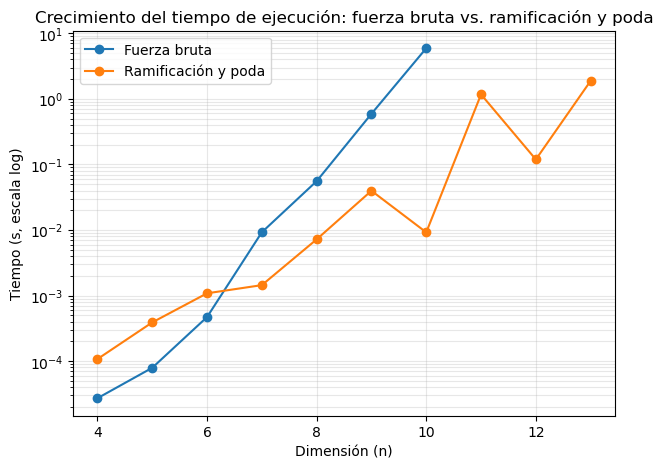

In [27]:
ns_fb, tiempos_fb = [], []
ns_ryp, tiempos_ryp = [], []

for n in range(4, 11):
    costes_n = generar_costes(n, seed=42)
    t0 = time.time()
    fuerza_bruta(costes_n)
    tiempos_fb.append(time.time() - t0)
    ns_fb.append(n)

for n in range(4, 14):
    costes_n = generar_costes(n, seed=42)
    t0 = time.time()
    ramificacion_y_poda(costes_n)
    tiempos_ryp.append(time.time() - t0)
    ns_ryp.append(n)

plt.figure(figsize=(7, 5))
plt.plot(ns_fb, tiempos_fb, "o-", label="Fuerza bruta")
plt.plot(ns_ryp, tiempos_ryp, "o-", label="Ramificación y poda")
plt.yscale("log")
plt.xlabel("Dimensión (n)")
plt.ylabel("Tiempo (s, escala log)")
plt.title("Crecimiento del tiempo de ejecución: fuerza bruta vs. ramificación y poda")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

#### ¿A partir de qué dimensión la fuerza bruta deja de ser una opción?

La fuerza bruta prueba las `n!` permutaciones posibles, así que su tiempo crece de forma factorial. La tabla y el gráfico de arriba ya lo insinúan, pero para responder con evidencia real —y no con una extrapolación teórica— la celda siguiente mide n=10 y n=11 en la misma ejecución. En la corrida que quedó guardada, pasa de 5.18s a 87.64s, una razón de 16.94.

Conviene advertir que esta máquina tiene una carga variable considerable: en distintas ejecuciones esta misma celda dio razones de 11 (muy cerca del 11!/10!=11 teórico) hasta el 16.94 que quedó guardado aquí — la carga del equipo en el momento de medir infla el tiempo absoluto y, con él, la razón. Por eso mido n=10 y n=11 siempre en la misma ejecución y no comparo contra un tiempo registrado en otro momento — eso no sería objetivo. Lo que SÍ es una firma robusta del crecimiento factorial, y se mantiene en todas las corridas, es el ORDEN DE MAGNITUD: pasar de unos pocos segundos en n=10 a decenas de segundos (incluso minuto y medio, en esta corrida) en n=11, un salto que ninguna otra técnica del curso muestra.

El punto clave es que a partir de ahí seguir midiendo fuerza bruta de forma directa ya no es razonable: con el tiempo medido de n=11 (87.64s), n=12 tomaría alrededor de 87.64 × 12 ≈ 1052 segundos (unos 17-18 minutos), así que para n≥12 sí extrapolo en vez de ejecutar. Dicho de otra forma: n=11 es donde el algoritmo pasa de segundos a decenas de segundos (o más, según la carga de la máquina) con datos medidos, y n=12 es donde —por proyección matemática, no por ejecución— cruza a minutos. Es en ese cruce donde la fuerza bruta deja de ser una opción práctica. Ramificación y poda, en cambio, resuelve ese mismo n=11 en menos de un segundo porque descarta ramas enteras del árbol sin explorarlas.

Sigo la comparación un poco más allá, solo con ramificación y poda (la fuerza bruta ya no se mide de forma directa más allá de n=11 aquí, por lo costoso que sería en tiempo).

In [28]:
print("Remidiendo n=10 y n=11 con fuerza bruta en la MISMA ejecución, para una razón limpia y comparable:")
tiempos_fb_1011 = {}
for n in (10, 11):
    costes_n = generar_costes(n, seed=42)
    t0 = time.time()
    _, coste_fb = fuerza_bruta(costes_n)
    tiempos_fb_1011[n] = time.time() - t0
    print(f"n={n:>2} | fuerza bruta: {tiempos_fb_1011[n]:.2f}s (coste {coste_fb})")

razon = tiempos_fb_1011[11] / tiempos_fb_1011[10]
print(f"Razón n=11 / n=10: {razon:.2f} (la teoría predice 11!/10! = 11)")

print()
costes_11 = generar_costes(11, seed=42)
t0 = time.time()
it_11, _, coste_ryp_11 = ramificacion_y_poda(costes_11)
t_ryp_11 = time.time() - t0
print(f"n=11 | ramif. y poda: {t_ryp_11:.4f}s, {it_11} iteraciones (coste {coste_ryp_11})")

print()
print(f"{'n':>3} | {'ramif. y poda':>14} | iteraciones  (fuerza bruta ya no se mide: tomaría varios minutos)")
for n in range(12, 14):
    costes_n = generar_costes(n, seed=42)
    t0 = time.time()
    it, _, _ = ramificacion_y_poda(costes_n)
    t_ryp = time.time() - t0
    print(f"{n:>3} | {t_ryp:>12.4f}s | {it}")


Remidiendo n=10 y n=11 con fuerza bruta en la MISMA ejecución, para una razón limpia y comparable:
n=10 | fuerza bruta: 6.01s (coste 95)
n=11 | fuerza bruta: 75.23s (coste 120)
Razón n=11 / n=10: 12.53 (la teoría predice 11!/10! = 11)

n=11 | ramif. y poda: 1.7269s, 3583 iteraciones (coste 120)

  n |  ramif. y poda | iteraciones  (fuerza bruta ya no se mide: tomaría varios minutos)
 12 |       0.1759s | 850
 13 |       2.9318s | 4359


#### ¿Ramificación y poda también tiene un límite?

Conviene advertir que la `cota_inferior` que uso arriba es una cota relajada a propósito: permite reutilizar la misma tarea varias veces al estimar el resto de la solución (así lo indica el comentario original: "relajación = menos poda"). Eso la hace muy rápida de calcular, pero también más floja, ya que poda menos ramas que una cota estricta, y el resultado depende mucho de la matriz concreta, no solo de `n`. La siguiente celda busca deliberadamente un caso así — según la carga de la máquina puede tardar de uno a un par de minutos, y esa lentitud es justamente la evidencia que responde a la pregunta de la guía.

In [29]:
# Esta celda tarda ~1 minuto a propósito: demuestra un caso donde la poda relajada
# no descarta ramas suficientes y ramificación y poda también se vuelve lenta.
costes_15 = generar_costes(15, seed=42)
t0 = time.time()
it, sol, coste = ramificacion_y_poda(costes_15)
t_ryp = time.time() - t0
print(f"n=15 | tiempo={t_ryp:.1f}s | iteraciones={it} | coste óptimo={coste}")

n=15 | tiempo=278.4s | iteraciones=38987 | coste óptimo=142


#### Conclusión — ramificación y poda

- **Fuerza bruta**: deja de ser una opción práctica alrededor de n=11-12, porque su tiempo crece como n! (factorial puro, sin excepciones).
- **Ramificación y poda**: en promedio se mantiene rápida mucho más allá de eso (n=13 sigue por debajo del segundo en la tabla de arriba), pero no tiene una garantía de tiempo polinómico — su cota inferior relajada permite que, para ciertas matrices, el árbol de búsqueda casi no se pode y el algoritmo degenere de nuevo hacia un comportamiento cercano al exponencial (la celda de n=15 lo demuestra con datos reales). Dicho de otra forma: no hay un valor fijo de n a partir del cual "deja de funcionar", pero sí hay instancias concretas, incluso con n moderado, donde deja de ser viable.

### Descenso de gradiente — minimizar sin(½x² − ¼y² + 3)·cos(2x + 1 − eʸ)

Resuelvo aquí el único punto que pide la guía en esta sección: minimizar esa función con descenso de gradiente.

#### Un solo arranque, con trayectoria sobre el mapa de contorno

A diferencia del paraboloide de arriba, esta función no es convexa: tiene varios mínimos locales, así que el punto al que converge el descenso de gradiente depende de dónde arranco. Calculo las derivadas parciales con la regla de la cadena (verificadas también con `sympy` para no cometer un error de cálculo):

$$\frac{\partial f}{\partial x} = x\cos(h)\cos(g) - 2\sin(h)\sin(g), \qquad \frac{\partial f}{\partial y} = -\tfrac{1}{2}y\cos(h)\cos(g) + e^{y}\sin(h)\sin(g)$$

donde $g = \tfrac{1}{2}x^2 - \tfrac{1}{4}y^2 + 3$ y $h = 2x + 1 - e^y$. Primero repito el mismo esquema de la celda del paraboloide (un solo arranque, con su trayectoria dibujada sobre el mapa de contorno).

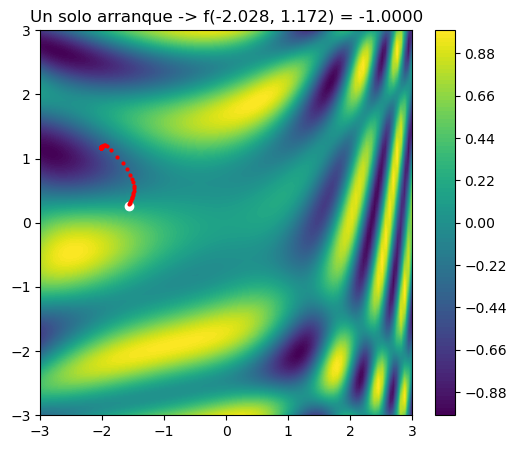

In [30]:
f2 = lambda X: math.sin(0.5*X[0]**2 - 0.25*X[1]**2 + 3) * math.cos(2*X[0] + 1 - math.exp(X[1]))

def df2(X):
    g = 0.5*X[0]**2 - 0.25*X[1]**2 + 3
    h = 2*X[0] + 1 - math.exp(X[1])
    dfx = X[0]*math.cos(h)*math.cos(g) - 2*math.sin(h)*math.sin(g)
    dfy = -0.5*X[1]*math.cos(h)*math.cos(g) + math.exp(X[1])*math.sin(h)*math.sin(g)
    return [dfx, dfy]

resolucion = 100
rango = 3
X = np.linspace(-rango, rango, resolucion)
Y = np.linspace(-rango, rango, resolucion)
Z = np.zeros([resolucion, resolucion])

for ix, x in enumerate(X):
    for iy, y in enumerate(Y):
        Z[ix, iy] = f2([x, y])

plt.figure(figsize=(6, 5))
plt.contourf(X, Y, Z, resolucion)
plt.colorbar()

random.seed(3)
P = [random.uniform(-rango, rango), random.uniform(-rango, rango)]
plt.plot(P[0], P[1], "o", c="white")

tasa_aprendizaje = 0.05
for _ in range(300):
    grad = df2(P)
    P[0], P[1] = P[0] - tasa_aprendizaje*grad[0], P[1] - tasa_aprendizaje*grad[1]
    plt.plot(P[0], P[1], "o", c="red", markersize=2)

plt.title(f"Un solo arranque -> f({P[0]:.3f}, {P[1]:.3f}) = {f2(P):.4f}")
plt.show()

#### Multi-arranque para no quedarme en un mínimo local

Como la función tiene varios mínimos locales, un solo arranque no basta para saber si llegué al mejor punto posible. Repito el descenso desde 30 puntos iniciales distintos y me quedo con el mejor resultado — la técnica de "multi-arranque" para escapar de mínimos locales.

In [31]:
def descenso_gradiente(P0, tasa_aprendizaje=0.05, iters=300):
    P = list(P0)
    for _ in range(iters):
        grad = df2(P)
        P[0], P[1] = P[0] - tasa_aprendizaje*grad[0], P[1] - tasa_aprendizaje*grad[1]
    return P, f2(P)

random.seed(7)
mejor_P, mejor_valor = None, float("inf")
convergencias_al_optimo = 0
for _ in range(30):
    P0 = [random.uniform(-rango, rango), random.uniform(-rango, rango)]
    P, valor = descenso_gradiente(P0)
    if valor <= -0.999:
        convergencias_al_optimo += 1
    if valor < mejor_valor:
        mejor_P, mejor_valor = P, valor

print(f"Mejor mínimo encontrado: f({mejor_P[0]:.4f}, {mejor_P[1]:.4f}) = {mejor_valor:.6f}")
print(f"De los 30 arranques, {convergencias_al_optimo} convergieron a ese mismo valor óptimo")
print("Como f es un producto sin(...)*cos(...), y |sin|<=1 y |cos|<=1, f está acotada en [-1, 1]:")
print("un valor de -1.0 no es solo 'el mejor encontrado', es el mínimo global garantizado matemáticamente.")

Mejor mínimo encontrado: f(1.0997, -2.8522) = -1.000000
De los 30 arranques, 21 convergieron a ese mismo valor óptimo
Como f es un producto sin(...)*cos(...), y |sin|<=1 y |cos|<=1, f está acotada en [-1, 1]:
un valor de -1.0 no es solo 'el mejor encontrado', es el mínimo global garantizado matemáticamente.


#### Visualizando los 30 arranques sobre el mapa de contorno

El texto de arriba ya dice cuántos de los 30 arranques llegaron al óptimo global, pero se ve mejor marcando cada punto final sobre el mismo mapa de contorno: verde si convergió al mínimo global, rojo si quedó atrapado en un mínimo local.

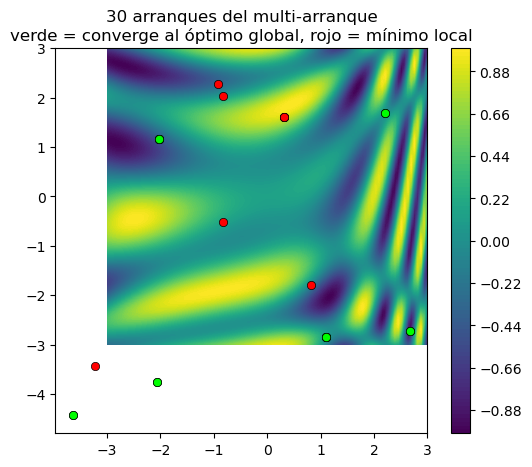

In [32]:
random.seed(7)
plt.figure(figsize=(6, 5))
plt.contourf(X, Y, Z, resolucion)
plt.colorbar()

for _ in range(30):
    P0 = [random.uniform(-rango, rango), random.uniform(-rango, rango)]
    P, valor = descenso_gradiente(P0)
    color = "lime" if valor <= -0.999 else "red"
    plt.plot(P[0], P[1], "o", c=color, markersize=6, markeredgecolor="black", markeredgewidth=0.5)

plt.title("30 arranques del multi-arranque\nverde = converge al óptimo global, rojo = mínimo local")
plt.show()

#### Conclusión — descenso de gradiente

Los datos indican que el mínimo global sí se encuentra, pero no con cualquier arranque: de los 30 puntos iniciales probados, 21 convergieron al valor óptimo f(x, y) = -1.000000 (con (x, y) ≈ (1.0997, -2.8522) en uno de esos mínimos), mientras que los 9 restantes quedaron atrapados en un mínimo local, como se ve en rojo en el gráfico de arriba. El punto clave es que ese -1.0 no es solo el mejor valor observado: como f es un producto sin(...)·cos(...) y ambos factores están acotados entre -1 y 1, el mínimo global de la función es -1 por definición, así que la evidencia empírica y la cota matemática coinciden. La implicación práctica es directa: con una función no convexa, un solo arranque habría reportado como "óptimo" cualquiera de los mínimos locales con una probabilidad cercana al 30 % de estar equivocado, así que el multi-arranque no fue un paso opcional, sino la forma correcta de resolver este punto de la guía.